<a href="https://colab.research.google.com/github/jessisam2007/24BAD049_24ADI006-DeepLearning/blob/main/24BAD049_DL_Expt6_LSTM_Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EXPT NO: 6 — Implementation of LSTM for Sentiment Analysis
**Roll No:** 24BAD049

## Part A: Dataset Preparation

In [ ]:
import re
import os
import numpy as np
import pandas as pd
from collections import Counter
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
import tarfile

ROLL_NO = "24BAD049"
print("Roll No:", ROLL_NO)

archive_path = tf.keras.utils.get_file(
    "aclImdb_v1.tar.gz",
    "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz",
    cache_dir=".", cache_subdir=""
)
with tarfile.open(archive_path) as tar:
    tar.extractall(".", filter="data")

def load_split(split):
    texts, labels = [], []
    for label, folder in [(0, "neg"), (1, "pos")]:
        path = os.path.join("aclImdb", split, folder)
        for fname in os.listdir(path):
            with open(os.path.join(path, fname), encoding="utf-8") as f:
                texts.append(f.read())
            labels.append(label)
    return texts, np.array(labels)

train_texts, train_labels = load_split("train")
test_texts, test_labels = load_split("test")
train_texts, train_labels = shuffle(train_texts, train_labels, random_state=42)
test_texts, test_labels = shuffle(test_texts, test_labels, random_state=42)

label_names = {0: "Negative", 1: "Positive"}
print("Training reviews:", len(train_texts), "| Test reviews:", len(test_texts))
for i in range(3):
    print(f"\nReview {i+1} -> Label: {train_labels[i]} ({label_names[int(train_labels[i])]})")
    print(train_texts[i][:250], "...")

print("\nSentiment classes: 0 = Negative, 1 = Positive")
print(pd.Series(train_labels).map(label_names).value_counts())

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_clean = [clean_text(t) for t in train_texts]
test_clean = [clean_text(t) for t in test_texts]
print("\nCleaned sample:", train_clean[0][:250], "...")

train_tokens = [t.split() for t in train_clean]
test_tokens = [t.split() for t in test_clean]
print("Tokens (first 15):", train_tokens[0][:15])

MAX_VOCAB = 10000
word_counts = Counter(w for tokens in train_tokens for w in tokens)
word_index = {"<PAD>": 0, "<OOV>": 1}
for idx, (word, _) in enumerate(word_counts.most_common(MAX_VOCAB - 2), start=2):
    word_index[word] = idx
VOCAB_SIZE = len(word_index)
print("Vocabulary size:", VOCAB_SIZE)

def to_sequence(tokens):
    return [word_index.get(w, 1) for w in tokens]

train_seq = [to_sequence(t) for t in train_tokens]
test_seq = [to_sequence(t) for t in test_tokens]
print("Sequence (first 15):", train_seq[0][:15])

MAX_LEN = 200
X_full = tf.keras.utils.pad_sequences(train_seq, maxlen=MAX_LEN, padding="pre", truncating="post")
X_test = tf.keras.utils.pad_sequences(test_seq, maxlen=MAX_LEN, padding="pre", truncating="post")
y_full = np.array(train_labels)
y_test = np.array(test_labels)
print("Padded training data shape:", X_full.shape)

X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42, stratify=y_full
)
print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)


Roll No: 24BAD049
Training reviews: 25000 | Test reviews: 25000

Review 1 -> Label: 0 (Negative)
Wow. I thought this might be insipid but it was even worse than I imagined! Sometimes I like to watch a good "car-crash" movie: those that are so bad that you can't look away because you want to see how bad they can possibly get. This is really the o ...

Review 2 -> Label: 1 (Positive)
<br /><br />I'm sure things didn't exactly go the same way in the real life of Homer Hickam as they did in the film adaptation of his book, Rocket Boys, but the movie "October Sky" (an anagram of the book's title) is good enough to stand alone. I hav ...

Review 3 -> Label: 0 (Negative)
*****probably minor spoilers******<br /><br />I cant say i liked it, but i cant say i didn't...its very strange. It has bad things in it like for example a shark that came out of nowhere with the worst CGI you can imagine,if i was the director i woul ...

Sentiment classes: 0 = Negative, 1 = Positive
Negative    12500
Positiv

## Part B: Implementing the LSTM Model

Roll No: 24BAD049


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329,473 (5.07 MB)

 Trainable params: 1,329,473 (5.07 MB)

 Non-trainable params: 0 (0.00 B)

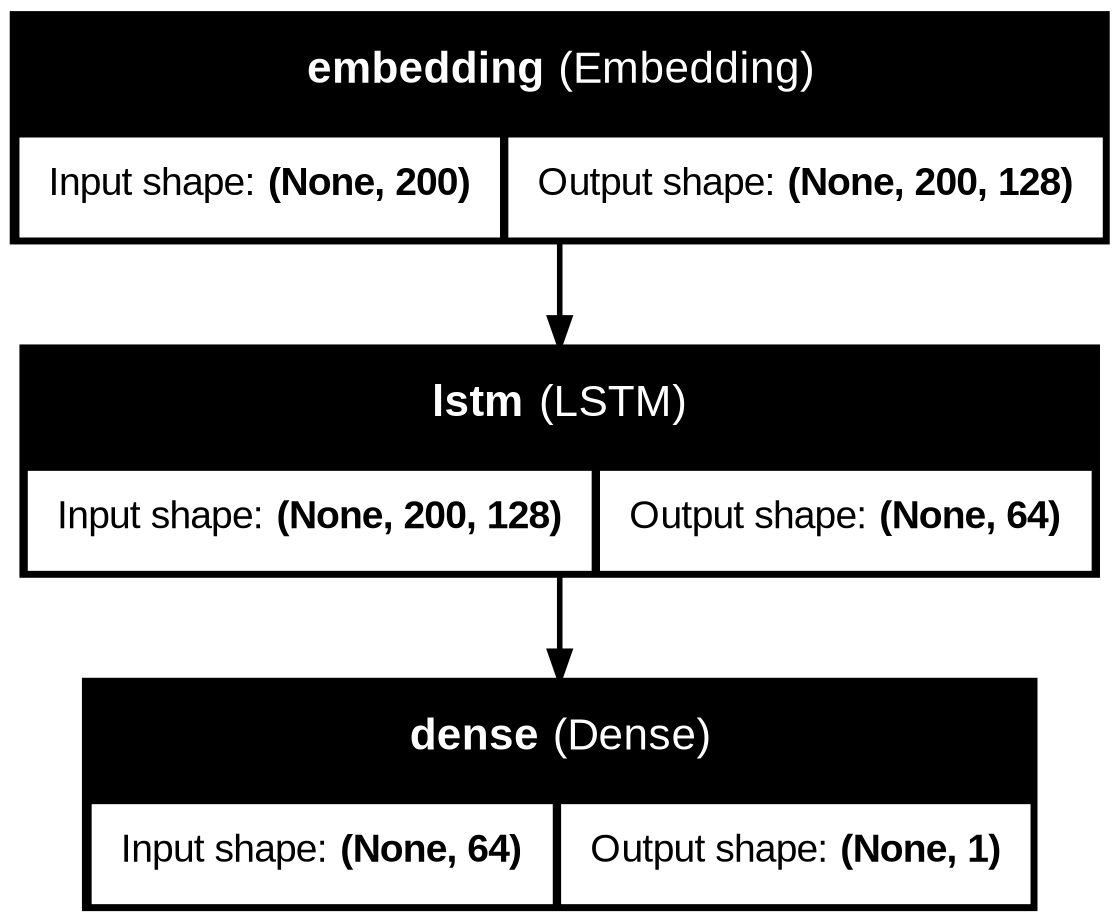

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from IPython.display import display

print("Roll No:", ROLL_NO)

model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=VOCAB_SIZE, output_dim=128),
    LSTM(64),
    Dense(1, activation="sigmoid")
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

model.summary()
display(tf.keras.utils.plot_model(model, show_shapes=True, show_layer_names=True))


## Part C: Model Training and Performance Evaluation

Roll No: 24BAD049
Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.7555 - loss: 0.4955 - val_accuracy: 0.8418 - val_loss: 0.3883
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8826 - loss: 0.2955 - val_accuracy: 0.8488 - val_loss: 0.3659
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9216 - loss: 0.2118 - val_accuracy: 0.8582 - val_loss: 0.3629
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9416 - loss: 0.1618 - val_accuracy: 0.8522 - val_loss: 0.4911
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9584 - loss: 0.1173 - val_accuracy: 0.8346 - val_loss: 0.4591

  Epoch  Training Accuracy  Validation Accuracy  Training Loss  Validation Loss
     1            0.75545               0.8418       0.495522         0.388325
     2            0.88260               0.8488       0.295525         0.365857
     3            0.92165               0.8582       0.211845         0.362914
     4            0.9415

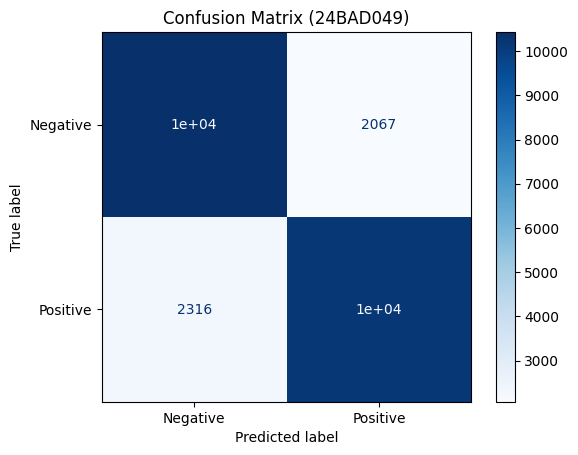

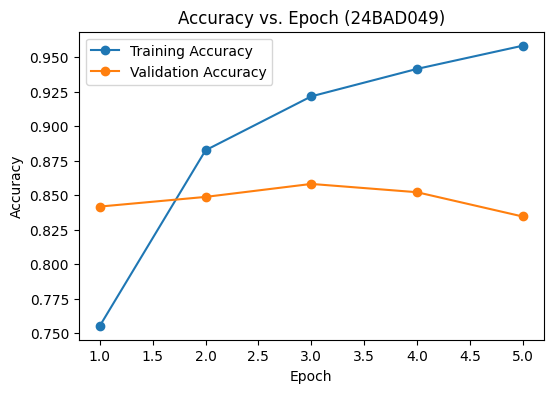

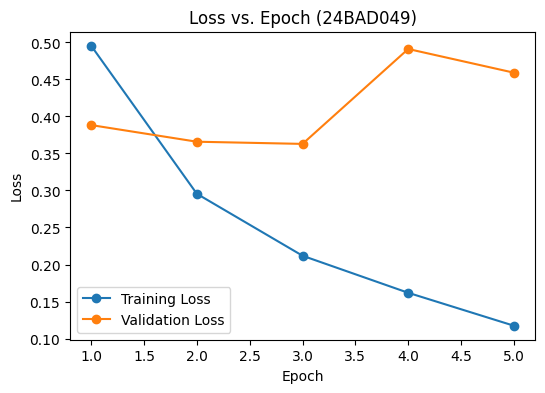

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("Roll No:", ROLL_NO)

history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_data=(X_val, y_val)
)

history_df = pd.DataFrame({
    "Epoch": range(1, len(history.history["loss"]) + 1),
    "Training Accuracy": history.history["accuracy"],
    "Validation Accuracy": history.history["val_accuracy"],
    "Training Loss": history.history["loss"],
    "Validation Loss": history.history["val_loss"],
})
print("\n", history_df.to_string(index=False))

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}")

y_prob = model.predict(X_test, verbose=0)
y_pred = (y_prob > 0.5).astype(int).ravel()
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(cmap="Blues")
plt.title(f"Confusion Matrix ({ROLL_NO})")
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(history_df["Epoch"], history_df["Training Accuracy"], marker="o", label="Training Accuracy")
plt.plot(history_df["Epoch"], history_df["Validation Accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title(f"Accuracy vs. Epoch ({ROLL_NO})")
plt.legend()
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(history_df["Epoch"], history_df["Training Loss"], marker="o", label="Training Loss")
plt.plot(history_df["Epoch"], history_df["Validation Loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"Loss vs. Epoch ({ROLL_NO})")
plt.legend()
plt.show()


## Part D: Sentiment Prediction and Deep Learning Experiment Management

In [ ]:
print("Roll No:", ROLL_NO)

def predict_sentiment(review):
    cleaned = clean_text(review)
    tokens = cleaned.split()
    seq = [word_index.get(w, 1) for w in tokens]
    padded = tf.keras.utils.pad_sequences([seq], maxlen=MAX_LEN,
                                          padding="pre", truncating="post")
    prob = float(model.predict(padded, verbose=0)[0][0])
    label = "Positive" if prob >= 0.5 else "Negative"
    return label, prob

new_reviews = [
    ("This movie was absolutely fantastic, the acting and story were brilliant.", "Positive"),
    ("A wonderful film with great performances. I loved every minute of it.", "Positive"),
    ("An emotional and beautifully directed movie that I would happily watch again.", "Positive"),
    ("This was a terrible movie. The plot was boring and the acting was awful.", "Negative"),
    ("I hated this film. It was a complete waste of time and money.", "Negative"),
    ("The story was weak, the dialogue was dull and the ending was disappointing.", "Negative"),
]

results = []
for review, expected in new_reviews:
    predicted, prob = predict_sentiment(review)
    results.append({
        "Review": review[:55] + "...",
        "Expected": expected,
        "Predicted": predicted,
        "Probability": round(prob, 4),
        "Match": "Yes" if predicted == expected else "No",
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))
print(f"\nCorrect predictions: {(results_df['Match'] == 'Yes').sum()} / {len(results_df)}")


Roll No: 24BAD049
                                                    Review Expected Predicted  Probability Match
This movie was absolutely fantastic, the acting and sto... Positive  Positive       0.8903   Yes
A wonderful film with great performances. I loved every... Positive  Positive       0.9875   Yes
An emotional and beautifully directed movie that I woul... Positive  Positive       0.9891   Yes
This was a terrible movie. The plot was boring and the ... Negative  Negative       0.0018   Yes
I hated this film. It was a complete waste of time and ... Negative  Negative       0.0093   Yes
The story was weak, the dialogue was dull and the endin... Negative  Negative       0.0117   Yes

Correct predictions: 6 / 6
